# Assignment 1: Thinking Like a Data Scientist

**CPSC 4300/6300 Applied Data Science**

This assignment combines short scenarios with an Asheville Airbnb case study based on Lab 01. Some questions ask for code, but the main focus is how you define a problem, make choices about data, and support an interpretation.

## Grading

| Part | Topic | Points |
|---|---|---:|
| A | Questions, variables, and data provenance | 10 |
| B | Data quality and preparation | 20 |
| C | Exploration and visualization | 20 |
| D | Asheville case study | 45 |
| E | Communication and AI reflection | 5 |
|  | **Total** | **100** |

Submit the completed `.ipynb` and an exported `.html` file. Before submitting, restart the kernel and run all cells. Show your reasoning, not just the final output.


## Use of AI tools

You may use an AI tool to discuss an idea, clarify syntax, or debug code. You are still responsible for the code you submit and for checking every claim against the data, course material, or documentation.

If you use an AI tool, identify the tool and model (if shown), the question where you used it, and the type of help it provided. Cite AI-generated wording, code, or ideas near the relevant answer and complete the disclosure in Q22. A short citation is sufficient:

> OpenAI, ChatGPT, response to “brief description of prompt,” accessed [date].

The required AI Copilot activities also belong in the Q22 disclosure. Do not substitute an AI response for your own analysis. AI-assisted work that is not disclosed may be treated as an academic-integrity issue.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# Part A (10 points). Questions, variables, and data provenance

## Q1 (3 points). From a broad request to an answerable question

A city transportation office has records on bus route, time of day, weather, delay minutes, and passenger count. A manager asks:

> “Can you analyze bus delays?”

Turn this request into three specific questions: one descriptive, one predictive, and one inferential. For each, say what evidence would help answer it. You do not need to build a model.

**Answer:** 
Descriptive - Can you analyze bus delays to tell me how the weather affects the number of bus riders on any given day?
Predictive - Can you predict bus passenger count based on the time of day and time of year, to say how holidays affect passenger count?
Inferential - Can you infer how time of day affects passenger count?

## Q2 (3 points). Unit of observation and variable meaning
**Unit of observation: what each row represents in a dataset.**

A university exports the following table:

| student_id | term | course_count | major_code | first_generation | cumulative_GPA |
|---|---|---:|---:|---|---:|
| 8102 | Fall 2025 | 5 | 112 | Yes | 3.42 |
| 8102 | Spring 2026 | 4 | 112 | Yes | 3.51 |
| 9137 | Fall 2025 | 4 | 205 | No | 2.88 |

Answer all parts:

1. What is the unit of observation? - A student, which pertains to each row.
2. Why is `student_id` numeric but not a quantitative variable? - Student_id is not quantitative, because the numbers are used to classify specific students, and is not fit for mathematical such as getting the median or calculations. 
3. How should `major_code` be treated? - It is nominal and categorical. Just like student_id, it is used to classify.
4. Which variable is binary categorical? First_generation.
5. A student appears in more than one row. Explain why treating rows as independent students would be misleading. If multiple rows can correspond to the same individual over time, if we did not treat them as independent students, then we'd ignore potential changes to one student's data. We need to know the historical data of one student's course count, major, and GPA.

**Answer:** 


## Q3 (4 points). Data source, sampling, and ethics

A restaurant owner wants to estimate customer satisfaction. An analyst suggests collecting only public one-star and five-star reviews from a popular review site because they are easy to classify.

Discuss three problems with this plan. Include at least one issue involving sampling or representation and one involving responsible data collection. Then outline a better way to collect the data.

**Answer:**

1. This plan introduces representation bias, by only considering 1 or 5 tar reviews. The owner will not be able to estimate customer satisfaction, because occluding 2-4 star reviews, skews the estimation to extreme dislikes and likes.
2. For responsible data collection, relying on on a single popular third party site, can introduce reliance on that single site itself.
3. Lastly, choosing 1 star and 5 star reviews only, will not provide good data. 2-4 star reviews consist of mixed reviews, that would tell the owner places to improve.
4. A better way to collect data would be to conduct customer surveys. This can be sent out via email, or in the shop, where they are prompted to answer the survey for a small incentive.

# Part B (20 points). Data quality and preparation 

## Q4 (5 points). Reshaping messy data

A campus café records the number of drinks sold as follows:


In [2]:
cafe_wide = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed"],
    "Coffee_8am": [32, 28, 35],
    "Tea_8am": [12, 15, 11],
    "Coffee_12pm": [41, 38, 46],
    "Tea_12pm": [18, 21, 19]
})
cafe_wide

,day,Coffee_8am,Tea_8am,Coffee_12pm,Tea_12pm
0,Mon,32,12,41,18
1,Tue,28,15,38,21
2,Wed,35,11,46,19


The column names hide two variables: `drink` and `time`.

1. State the unit of observation in the current table.
2. State the desired unit of observation for a tidy table.
3. Reshape the data into columns `day`, `drink`, `time`, and `count`.

4. Verify that the total number of drinks is unchanged after reshaping.
5. Explain one analysis that becomes easier after reshaping.


In [3]:
cafe_test = cafe_wide.melt()
cafe_test










,variable,value
0,day,Mon
1,day,Tue
2,day,Wed
3,Coffee_8am,32
4,Coffee_8am,28
5,Coffee_8am,35
6,Tea_8am,12
7,Tea_8am,15
8,Tea_8am,11
9,Coffee_12pm,41


In [4]:
# YOUR CODE HERE
cafe_long = cafe_wide.melt(id_vars="day", var_name="drink_time", value_name="count")
cafe_long[["drink", "time"]] = cafe_long["drink_time"].str.split("_", expand=True)
cafe_long = cafe_long[["day", "drink", "time", "count"]]
cafe_long

,day,drink,time,count
0,Mon,Coffee,8am,32
1,Tue,Coffee,8am,28
2,Wed,Coffee,8am,35
3,Mon,Tea,8am,12
4,Tue,Tea,8am,15
5,Wed,Tea,8am,11
6,Mon,Coffee,12pm,41
7,Tue,Coffee,12pm,38
8,Wed,Coffee,12pm,46
9,Mon,Tea,12pm,18


In [5]:
#to verify the total number of drinks are unchanced after reshaping
print("Original total:", cafe_wide.drop(columns="day").sum().sum())
print("Reshaped total:", cafe_long["count"].sum())

Original total: 316
Reshaped total: 316


**Explanation:**

Reshaping the dataset from wide to tidy (pd.melt()) preserves the total drink count and simply rearranges them into a single column. In the original wide format, the sales were spread across multiple columns. Melting those columns into a single count variable and splitting the variable names into drink and time columns, represent a unique day and drink and time combination, while maintaing exact same underlying sum of 316 drinks. 

Anthropic, Claude, response to “brief description of prompt,” accessed 9-23-26.

## Q5 (5 points). Missing values can mean different things

A community health survey contains the following missing values:

- `pregnancy_status` is blank for many respondents;
- `annual_income` is blank for some respondents who selected “prefer not to answer”;
- `blood_pressure` is blank when a clinic device failed;
- `followup_date` is blank for patients who have not yet been scheduled.

For each variable, decide whether the blank most likely means **not applicable**, **withheld**, **measurement failure**, **not yet observed**, or **uncertain**. Why would replacing all four with 0 be inappropriate? Choose one variable and describe what you would check before deciding how to handle it.

**Answer:**

Pregnancy status - likely not applicable for respondents who cannot be pregnant.
annual_income - witheld
blood_pressue - measurement failure
followup_date - not yet observed

## Q6 (6 points). Table integration and row multiplication

The following tables describe customers and their orders.


In [6]:
customers = pd.DataFrame({
    "customer_id": [101, 102, 103, 104],
    "city": ["Clemson", "Greenville", "Anderson", "Clemson"],
    "signup_year": [2023, 2024, 2024, 2025]
})

orders = pd.DataFrame({
    "order_id": [501, 502, 503, 504, 505],
    "customer_id": [101, 101, 103, 105, 103],
    "amount": [32, 18, 99, 45, 27]
})

display(customers)
display(orders)

,customer_id,city,signup_year
0,101,Clemson,2023
1,102,Greenville,2024
2,103,Anderson,2024
3,104,Clemson,2025


,order_id,customer_id,amount
0,501,101,32
1,502,101,18
2,503,103,99
3,504,105,45
4,505,103,27


1. What is the key used to integrate these tables?
2. Predict the number of rows in a left join with `customers` on the left. Explain your prediction before running the join.
3. Perform the join and verify the result.
4. Why does customer 101 appear twice?
5. Which customer has no matching order? Which order has no matching customer?
6. If the analytical unit should remain one row per customer, explain why this raw join is not yet analysis-ready and create a customer-level table containing total order amount.


In [7]:
# YOUR CODE HERE
# 1. The key is customer_id
# 2.
merged = customers.merge(orders, on="customer_id", how="left")
print(len(merged))
merged

6


,customer_id,city,signup_year,order_id,amount
0,101,Clemson,2023,501.0,32.0
1,101,Clemson,2023,502.0,18.0
2,102,Greenville,2024,NaN,NaN
3,103,Anderson,2024,503.0,99.0
4,103,Anderson,2024,505.0,27.0
5,104,Clemson,2025,NaN,NaN


In [8]:
cust_totals = (orders.groupby("customer_id", as_index=False)["amount"].sum()
               .rename(columns={"amount": "total_amount"}))
customer_level = customers.merge(cust_totals, on="customer_id", how="left")
customer_level["total_amount"] = customer_level["total_amount"].fillna(0)
customer_level

,customer_id,city,signup_year,total_amount
0,101,Clemson,2023,50.0
1,102,Greenville,2024,0.0
2,103,Anderson,2024,126.0
3,104,Clemson,2025,0.0


**Explanation:**


## Q7 (4 points). Who is removed by a cleaning rule?

A housing analyst plans to remove every row containing a missing value. The dataset has 40 columns. Older homes often lack renovation dates, while newer homes usually have complete records.

How could complete-case deletion change the group of homes represented in the cleaned data? Describe two checks you would make before deleting any rows, and suggest a more targeted approach.

**Answer:**
The cleaned dataset would end up heavily skewed toward newer homes (or recently renovated ones) with complete administrative records. This introduces selection bias, meaning any conclusions about housing values, condition, or features will not generalize to the entire housing stock.

# Part C (20 points). Exploration and visualization

## Q8 (7 points). Same summaries, different structures

The next cell creates Anscombe’s Quartet. The four datasets have nearly identical common summary statistics.


In [9]:
x_common = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = pd.DataFrame({
    "x1": x_common,
    "y1": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
    "x2": x_common,
    "y2": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
    "x3": x_common,
    "y3": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
    "x4": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "y4": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]
})
anscombe

,x1,y1,x2,y2,x3,y3,x4,y4
0,10,8.04,10,9.14,10,7.46,8,6.58
1,8,6.95,8,8.14,8,6.77,8,5.76
2,13,7.58,13,8.74,13,12.74,8,7.71
3,9,8.81,9,8.77,9,7.11,8,8.84
4,11,8.33,11,9.26,11,7.81,8,8.47
5,14,9.96,14,8.10,14,8.84,8,7.04
6,6,7.24,6,6.13,6,6.08,8,5.25
7,4,4.26,4,3.10,4,5.39,19,12.50
8,12,10.84,12,9.13,12,8.15,8,5.56
9,7,4.82,7,7.26,7,6.42,8,7.91


1. For each pair `(x1, y1)` through `(x4, y4)`, calculate mean, standard deviation, and correlation.
2. Plot all four datasets using the same axis limits.
3. Describe the structural difference visible in each plot.
4. Explain why the summary statistics alone are insufficient.
5. Identify the dataset in which one observation largely determines the apparent relationship.


Set 1: mean_x=9.00, mean_y=7.50, std_x=3.32, std_y=2.03, corr=0.816
Set 2: mean_x=9.00, mean_y=7.50, std_x=3.32, std_y=2.03, corr=0.816
Set 3: mean_x=9.00, mean_y=7.50, std_x=3.32, std_y=2.03, corr=0.816
Set 4: mean_x=9.00, mean_y=7.50, std_x=3.32, std_y=2.03, corr=0.817


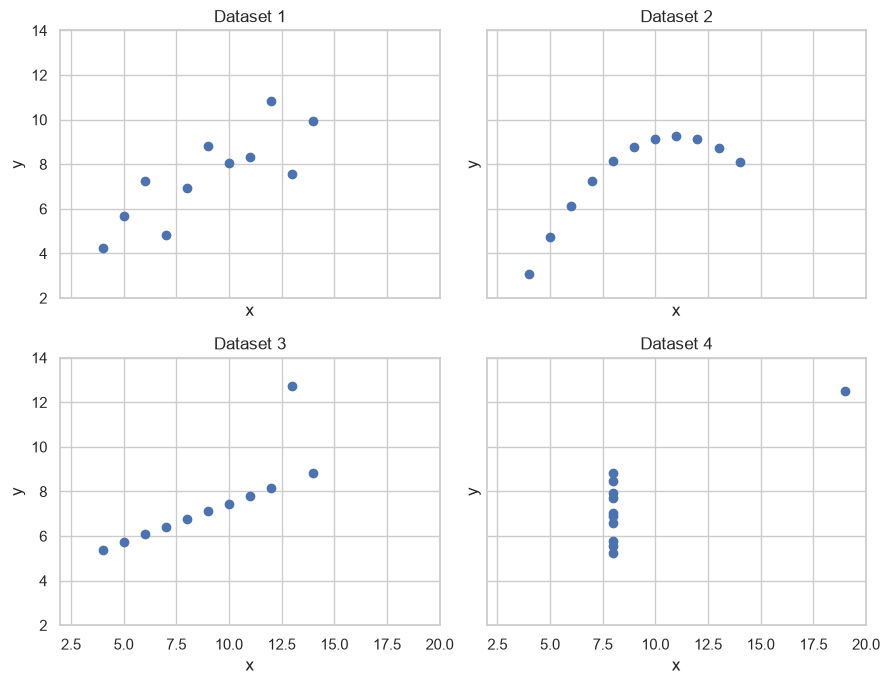

In [10]:
# YOUR CODE HERE
for i in range(1, 5):
    x, y = anscombe[f"x{i}"], anscombe[f"y{i}"]
    print(f"Set {i}: mean_x={x.mean():.2f}, mean_y={y.mean():.2f}, "
          f"std_x={x.std():.2f}, std_y={y.std():.2f}, corr={x.corr(y):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat, start=1):
    ax.scatter(anscombe[f"x{i}"], anscombe[f"y{i}"])
    ax.set_title(f"Dataset {i}")
    ax.set_xlim(2, 20)
    ax.set_ylim(2, 14)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

#Sorry if this looks weird, didn't know to put this in interpretation or not.
# Anthropic, Claude, response to “Given this panda dataframe "x_common = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
# anscombe = pd.DataFrame({
#     "x1": x_common,
#     "y1": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
#     "x2": x_common,
#     "y2": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
#     "x3": x_common,
#     "y3": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
#     "x4": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
#     "y4": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]
# })
# anscombe” do "For each pair (x1, y1) through (x4, y4), calculate mean, standard deviation, and correlation.
# Plot all four datasets using the same axis limits."" accessed 9-24-26.

**Interpretation:**
Dataset 1 - A positive linear relationship.
Dataset 2 - A A smooth curved relationship that's not a straight line. Quadratic-like.
Dataset 3 - An almost perfectly linear positive relationship. 
Dataset 4 - A vertically clustered line with a mean 7.5.

## Q9 (5 points). Choosing a chart

Choose one main visualization for each question and briefly justify it. For any two questions, also name a plausible but weaker choice and explain the drawback.

1. How are employee commute times distributed?
2. How did monthly electricity use change during 2025?
3. Do engine size and fuel consumption move together?
4. How does salary distribution differ across four job levels?
5. Which of eight product categories had the most returns?

**Answer:**
1. Choice - Histogram
Justification: Commute time is a continuous numeric variable, making a histogram ideal for showing shape, skewness, and central tendency across intervals.
Weaker Choice: Bar chart - Treating each distinct commute time value as an individual category creates an overly cluttered x-axis with empty spaces, obscuring the underlying distribution pattern.
2. Choice - Line chart
Justification: Line charts can highlight trends over ordered time intervals , such as months of the year.
Weaker Choice: Pie chart  Pie charts  destroy the chronological flow of time and make comparing monthly changes difficult due to human difficulty in judging slice angles.
3. Main Choice - Scatter plot
Justification: Scatter plots are designed to show relationships, correlation, and clustering between two quatitative variables.
4. Main Choice - Box plots (or Ridge plots / Violin plots)
Justification: Box plots allow for direct visual comparison of key summary statistics (median, interquartile range, potential outliers) across categorical groups.
5. Main Choice - Bar chart 

Justification: A bar chart ordered by values. Categorical variables paired with counts are most clearly compared using bar height, making the highest value immediately recognizable for humans.

## Q10 (4 points). Correct numbers, misleading display

A report compares average wait times at two clinics: 31 minutes at Clinic A and 34 minutes at Clinic B. The bar chart begins at 30 minutes, so Clinic B's bar appears four times taller.

Why is this display misleading even though the two values are correct? Describe or create a better display. Is a truncated axis always inappropriate, or does the answer depend on the context?

**Answer:**  Starting the bar chart at 30 distorts the visual proportion. Starting at 30 would make 34 distorted, as those 4 units are more scaled, somewhat mimicking a zoomed in representation of an pixelated image (may not be the best definition). A better display could simply be... a bar chart that starts at 0 or a histogram.

In [11]:
# Optional: create your revised visualization here.

## Q11 (4 points). Outlier, error, or important case?

A delivery-time dataset contains one delivery that took 1,440 minutes. Give three possible explanations: a data-entry error, a genuine extreme case, and a mismatch in the definition of the variable. For each possibility, say what you would check and how you would handle the record. Do not assume that it should be deleted.

**Answer:**
1. Data entry - It could be a potential input error by the person putting it in. I would check who put it in. I would then check for the order details. Details being when the order was placed, who delivered the order, the distance of the deliver.
2. Genuine Extreme case - Could be a lost package, failed delivery attempt, bad weather, sent to wrong address, returned order. It is possible that the sysem defaulted to 24 hours.
3. Definition mismatch - Check if the columns and rows are consistent in the delivery dictionary.

# Part D (45 points). Asheville case study

Use `Asheville_listings.csv` for the remaining questions. As in Lab 01, each row represents one Airbnb listing. You may reuse code from the lab, but the analysis and interpretation here should address the new questions below.


In [12]:
df_raw = pd.read_csv("listings.csv")
df = df_raw.copy()

print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Shape: (2852, 18)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,155305,Cottage! BonPaul + Sharky's Hostel,746673,BonPaul,NaN,28806,35.578640,-82.595780,Entire home/apt,96.0,1,463,2025-09-01,2.69,8,70,23,NaN
1,197263,Tranquil Room & Private Bath,961396,Timothy,NaN,28806,35.577350,-82.638040,Private room,44.0,2,90,2025-09-01,0.56,2,88,3,NaN
2,209068,Terrace Cottage,1029919,Kevin,NaN,28804,35.617641,-82.551819,Entire home/apt,90.0,30,67,2025-05-03,0.39,1,268,2,NaN
3,246315,Asheville Dreamer's Cabin,1292070,Annie,NaN,28805,35.596150,-82.506350,Private room,62.0,7,53,2019-10-30,0.31,3,70,0,NaN
4,314540,Asheville Urban Farmhouse Entire Home 4.6 mi t...,381660,Tom,NaN,28806,35.585610,-82.627310,Entire home/apt,221.0,1,36,2025-06-23,0.22,1,180,7,NaN


,dtype
id,int64
name,str
host_id,int64
host_name,str
neighbourhood_group,float64
neighbourhood,int64
latitude,float64
longitude,float64
room_type,str
price,float64


## Q12 (5 points). Understanding the variables

Choose three columns from the Asheville dataset:

1. a quantitative variable;
2. a categorical variable; and
3. a variable whose meaning or appropriate use is not immediately clear.

For each one, explain what it represents, give one piece of evidence from the observed values or documentation, and say how you would treat it in an analysis.

### AI Copilot Activity 1: Understanding the dataset

Give an AI assistant the column names and data types, but not the full dataset. Ask it to classify the variables and point out anything that may need further investigation before analyzing price.

Include one useful suggestion from the AI response and one claim that needs to be checked. Show how you checked, or would check, that claim using the data or documentation.

**Answer:**

| | Variable | What it represents | Evidence from the data | How I treat it |
|---|---|---|---|---|
| Quantitative | `price` | The nightly price of a listing in dollars (the assignment describes it as cost per night) | 2,537 recorded values. Min 18, median 133, mean 196.38, max 9,999. | Numeric. It is right-skewed, so I summarize it with the median and quartiles, and I check extreme values before using the mean. |
| Categorical | `room_type` | The kind of space rented | 4 categories: Entire home/apt (2,566), Private room (266), Hotel room (12), Shared room (8). | Nominal categorical. I compare groups and always report group sizes, because Hotel room and Shared room are tiny. |
| Unclear meaning | `neighbourhood` | Looks like a neighbourhood name, but it holds numbers | 8 unique values, all 5-digit codes (28806, 28801, 28803, 28804, 28805, 28704, 28715, 28732). They look like ZIP codes. | Stored as an integer, but it is a category. I convert it to text or a category so I never average it. I would confirm the meaning in the data source documentation. |

*Prompt given to the AI:* the 18 column names and their data types (no rows).

*Useful suggestion from the AI: Treat neighbourhood as a categorical variable even though its datatype is int64, because a numeric code is a label, not a quantity. I confirmed this: the column has only 8 distinct 5-digit values, and averaging them has no meaning.

*Claim that needs checking:* that `price` values are plausible nightly rates. A column name and a dtype cannot show this. I checked with `df["price"].describe()` and by sorting the largest values. The minimum (18) looks fine, but three listings have a price of exactly 9,999, which looks like a placeholder, so the claim does not hold for every row. I would also check the data documentation for the currency and the rate definition.

*Citation:* Anthropic, Claude, response to "classify these variables <pasted them in> and point out what to check before analyzing price," accessed 9-25-26.


In [13]:
# Evidence for Q12
print("price (quantitative):")
print(df["price"].describe().round(2))
print()
print("room_type (categorical):")
print(df["room_type"].value_counts())
print()
print("neighbourhood (looks numeric, but it is a code):")
print("unique values:", df["neighbourhood"].nunique())
print(sorted(df["neighbourhood"].unique()))
print()
print("Largest prices:")
print(df["price"].sort_values(ascending=False).head(5).tolist())

price (quantitative):
count    2537.00
mean      196.38
std       405.67
min        18.00
25%        95.00
50%       133.00
75%       211.00
max      9999.00
Name: price, dtype: float64

room_type (categorical):
room_type
Entire home/apt    2566
Private room        266
Hotel room           12
Shared room           8
Name: count, dtype: int64

neighbourhood (looks numeric, but it is a code):
unique values: 8
[np.int64(28704), np.int64(28715), np.int64(28732), np.int64(28801), np.int64(28803), np.int64(28804), np.int64(28805), np.int64(28806)]

Largest prices:
[9999.0, 9999.0, 9999.0, 6847.0, 2558.0]


## Q13 (5 points). Missing columns are not all the same

Suppose someone suggests deleting every column that contains a missing value. Use a missing-value summary to show why this rule is too broad.

Identify one column that is entirely empty and decide what to do with it. Then choose one partially missing column and decide whether to keep it, drop it, or transform it. Report how many rows are affected and explain what information would be lost if all columns with missing values were removed.


In [14]:
# Audit the proposed missing-value rule and support your recommendation.

# YOUR CODE HERE
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)
display(missing)

print("Columns in the file:", df.shape[1])
print("Columns with at least one missing value:", (df.isna().sum() > 0).sum())
print("Rows with at least one missing value:", df.isna().any(axis=1).sum(), "of", len(df))

# Columns that are entirely empty
empty_cols = [c for c in df.columns if df[c].isna().all()]
print("Entirely empty columns:", empty_cols)

# Partially missing column I chose to transform: reviews_per_month
rpm_missing = df["reviews_per_month"].isna()
print("reviews_per_month missing rows:", rpm_missing.sum(), f"({rpm_missing.mean()*100:.1f}%)")

,missing_count,missing_pct
neighbourhood_group,2852,100.00
license,2852,100.00
price,315,11.04
last_review,243,8.52
reviews_per_month,243,8.52
host_name,3,0.11


Columns in the file: 18
Columns with at least one missing value: 6
Rows with at least one missing value: 2852 of 2852
Entirely empty columns: ['neighbourhood_group', 'license']
reviews_per_month missing rows: 243 (8.5%)


**Answer:**
Six of the 18 columns have missing values, but they are missing for different reasons and they matter differently.

I would drop the entirely empty columns, since they carry no values. 
For partially missing columns, 
I would transform reviews_per_month and not drop it. It is missing in 243 rows (8.5%). Q14 shows that all 243 also have 0 total reviews, so the blank means "no reviews yet", and the rate is 0 for those rows.

## Q14 (6 points). What does a missing review rate mean?

Consider two simple rules for missing `reviews_per_month` values: replace all of them with 0, or leave all of them missing. Check `number_of_reviews` and at least one other relevant variable to see whether either rule works for every row.

Based on what you find, write a rule for handling these values and report how many rows are covered by each part of the rule. Compare one summary before and after the change. Did the result behave as expected?

### AI Copilot Activity 2: A cleaning hypothesis

Ask an AI assistant why `reviews_per_month` might be missing and what should be checked before replacing the missing values with 0. Summarize its recommendation, compare it with your results, and explain your final choice.


In [15]:
# Compare the two blanket rules and gather evidence for a conditional rule.

# YOUR CODE HERE
rpm_missing = df["reviews_per_month"].isna()
missing_rows = df[rpm_missing]
present_rows = df[~rpm_missing]

print("Rows with missing reviews_per_month:", rpm_missing.sum())
print()
print("Among the missing rows:")
print("  number_of_reviews equal to 0:", (missing_rows["number_of_reviews"] == 0).sum())
print("  number_of_reviews_ltm equal to 0:", (missing_rows["number_of_reviews_ltm"] == 0).sum())
print("  last_review also missing:", missing_rows["last_review"].isna().sum())
print()
print("Among rows where reviews_per_month is present:")
print("  rows with number_of_reviews equal to 0:", (present_rows["number_of_reviews"] == 0).sum())
print()
print("Rows with reviews but a missing rate:", ((df['number_of_reviews'] > 0) & rpm_missing).sum())

Rows with missing reviews_per_month: 243

Among the missing rows:
  number_of_reviews equal to 0: 243
  number_of_reviews_ltm equal to 0: 243
  last_review also missing: 243

Among rows where reviews_per_month is present:
  rows with number_of_reviews equal to 0: 0

Rows with reviews but a missing rate: 0


**AI recommendation:**
(Anthropic, Claude, response to "why might reviews_per_month be missing and what should I check before replacing with 0," accessed 9-25-26.)
 The AI said a review rate is usually missing because a listing has no reviews yet, so the rate cannot be computed. It recommended checking that number_of_reviews is 0 (and `last_review` is blank) before replacing with 0, because a listing with reviews but a missing rate would be a data problem, and 0 would be wrong for it.

**Evidence from the data:** 243 rows are missing from reviews_per_month.  None of the 2,609 rows with a rate has 0 total reviews. No row has reviews but a missing rate. So "leave all missing" throws away a meaningful 0, and "replace all with 0" happens to give the right answer for every row in this file.

**Decision:**
I use a conditional rule so it stays correct if the data changes. 

In [16]:
# Implement your conditional rule only after documenting it above.
# Compare one relevant summary before and after the change.

# YOUR CODE HERE
before = df["reviews_per_month"].copy()

df["reviews_per_month_clean"] = df["reviews_per_month"]
rule_zero = df["reviews_per_month"].isna() & (df["number_of_reviews"] == 0)
df.loc[rule_zero, "reviews_per_month_clean"] = 0

print("Rows set to 0 by the rule:", rule_zero.sum())
print("Rows left missing (missing but has reviews):",
      (df["reviews_per_month"].isna() & (df["number_of_reviews"] > 0)).sum())
print("Rows unchanged:", (~df["reviews_per_month"].isna()).sum())
print()

summary = pd.DataFrame({
    "before": [before.count(), before.mean(), before.median()],
    "after": [df["reviews_per_month_clean"].count(),
              df["reviews_per_month_clean"].mean(),
              df["reviews_per_month_clean"].median()]
}, index=["non-missing count", "mean", "median"]).round(3)
display(summary)

Rows set to 0 by the rule: 243
Rows left missing (missing but has reviews): 0
Rows unchanged: 2609



,before,after
non-missing count,2609.000,2852.000
mean,2.178,1.992
median,1.640,1.435


## Q15 (6 points). What is a typical price?

A tourism report plans to state: **“The average Asheville Airbnb costs $X per night.”**

Create `df_price` using listings with a recorded price. Report how many rows were excluded and the corresponding percentage. Use numerical summaries and visualization(s) to decide whether the mean gives a fair picture of a typical listing.

Compare at least two measures of a typical price and show both the full distribution and the range containing most listings. Then write a more informative one-sentence statement for the report. Why are listings with missing prices unusable for this question but not necessarily bad records?


Rows in df: 2852
Rows in df_price: 2537
Rows excluded: 315 (11.04%)

Mean: 196.38
Median: 133.0
5% trimmed mean: 158.18
Most common price (mode): 100.0
Std deviation: 405.67
Skewness: 18.93
Share of listings priced below the mean: 71.3%

0.05     57.0
0.25     95.0
0.50    133.0
0.75    211.0
0.95    428.6
Name: price quantiles, dtype: float64

Missing-price rows with availability_365 = 0: 187 of 315
Share of priced rows with availability_365 = 0: 1.0%


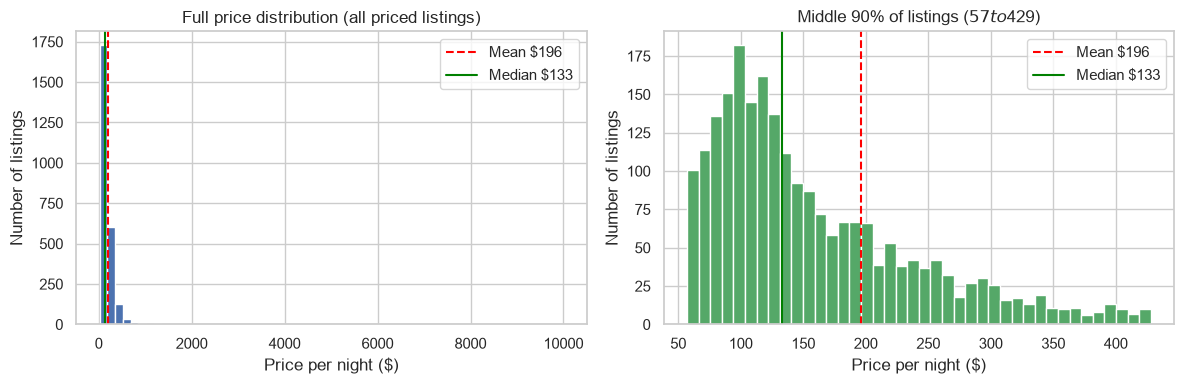

In [17]:
# Create df_price, report exclusions, and produce the evidence needed
# to evaluate the tourism report's proposed statement.

# YOUR CODE HERE
# df_price: listings with a recorded price
df_price = df[df["price"].notna()].copy()
excluded = len(df) - len(df_price)
print("Rows in df:", len(df))
print("Rows in df_price:", len(df_price))
print(f"Rows excluded: {excluded} ({excluded / len(df) * 100:.2f}%)")
print()

p = df_price["price"]
trimmed = p[(p >= p.quantile(0.05)) & (p <= p.quantile(0.95))]
print("Mean:", round(p.mean(), 2))
print("Median:", p.median())
print("5% trimmed mean:", round(trimmed.mean(), 2))
print("Most common price (mode):", p.mode().iloc[0])
print("Std deviation:", round(p.std(), 2))
print("Skewness:", round(p.skew(), 2))
print(f"Share of listings priced below the mean: {(p < p.mean()).mean() * 100:.1f}%")
print()
print(p.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).rename("price quantiles"))

# Why are prices missing? Compare availability
print()
print("Missing-price rows with availability_365 = 0:",
      (df[df['price'].isna()]['availability_365'] == 0).sum(), "of", excluded)
print(f"Share of priced rows with availability_365 = 0: "
      f"{(df_price['availability_365'] == 0).mean() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(p, bins=60, color="#4c72b0")
axes[0].axvline(p.mean(), color="red", linestyle="--", label=f"Mean ${p.mean():.0f}")
axes[0].axvline(p.median(), color="green", linestyle="-", label=f"Median ${p.median():.0f}")
axes[0].set_title("Full price distribution (all priced listings)")
axes[0].set_xlabel("Price per night ($)")
axes[0].set_ylabel("Number of listings")
axes[0].legend()

low, high = p.quantile(0.05), p.quantile(0.95)
middle = p[(p >= low) & (p <= high)]
axes[1].hist(middle, bins=40, color="#55a868")
axes[1].axvline(p.mean(), color="red", linestyle="--", label=f"Mean ${p.mean():.0f}")
axes[1].axvline(p.median(), color="green", linestyle="-", label=f"Median ${p.median():.0f}")
axes[1].set_title(f"Middle 90% of listings (${low:.0f} to ${high:.0f})")
axes[1].set_xlabel("Price per night ($)")
axes[1].set_ylabel("Number of listings")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation:**
To answer "Why are listings with missing prices unusable for this question but not necessarily bad records?": it's because they indicate listing status. The property could be inactive for the time being, but they still remain valuable for other analysis concerning room_type, neighborhood, etc.
The distribution is right skewed heavily. 

## Q16 (6 points). Should the price outliers be removed?

Suppose the platform removes every price flagged by the 1.5 × IQR rule before publishing a dashboard. Find the flagged listings and inspect at least two other variables that may help explain the high prices. Compare one result before and after the listings are removed.

Would you keep this rule, modify it, or reject it? In your answer, distinguish what the IQR rule can detect from what it cannot tell us. Also discuss which type of listing may be lost and what you would check before deleting a record.


In [18]:
# Audit the proposed IQR-based deletion policy and quantify its effect.

# YOUR CODE HERE
p = df_price["price"]
q1, q3 = p.quantile(0.25), p.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Lower fence = {lower_fence}, upper fence = {upper_fence}")

flagged = df_price[(df_price["price"] < lower_fence) | (df_price["price"] > upper_fence)]
kept = df_price.drop(flagged.index)
print(f"Flagged listings: {len(flagged)} ({len(flagged) / len(df_price) * 100:.1f}% of df_price)")
print("Flagged below the lower fence:", (df_price["price"] < lower_fence).sum())
print()

print("Room type share, flagged vs all priced listings:")
print(pd.DataFrame({
    "flagged_count": flagged["room_type"].value_counts(),
    "flagged_pct": (flagged["room_type"].value_counts(normalize=True) * 100).round(1),
    "all_priced_pct": (df_price["room_type"].value_counts(normalize=True) * 100).round(1),
}).fillna(0))
print()

cols = ["minimum_nights", "availability_365", "number_of_reviews", "calculated_host_listings_count"]
compare = pd.DataFrame({
    "flagged_median": flagged[cols].median(),
    "kept_median": kept[cols].median(),
    "flagged_mean": flagged[cols].mean().round(1),
    "kept_mean": kept[cols].mean().round(1),
})
display(compare)

print("Flagged listings with 0 reviews:", (flagged["number_of_reviews"] == 0).sum())
print("Flagged listings with availability_365 = 0:", (flagged["availability_365"] == 0).sum())
print()

before_after = pd.DataFrame({
    "before (all priced)": [len(df_price), df_price["price"].mean(), df_price["price"].median(), df_price["price"].std()],
    "after (IQR removal)": [len(kept), kept["price"].mean(), kept["price"].median(), kept["price"].std()],
}, index=["rows", "mean", "median", "std"]).round(2)
display(before_after)

print("Top 8 flagged listings by price:")
display(flagged.sort_values("price", ascending=False)[
    ["name", "price", "room_type", "availability_365", "number_of_reviews", "calculated_host_listings_count"]
].head(8))

Q1 = 95.0, Q3 = 211.0, IQR = 116.0
Lower fence = -79.0, upper fence = 385.0
Flagged listings: 173 (6.8% of df_price)
Flagged below the lower fence: 0

Room type share, flagged vs all priced listings:
                 flagged_count  flagged_pct  all_priced_pct
room_type                                                  
Entire home/apt          167.0         96.5            90.9
Hotel room                 1.0          0.6             0.4
Private room               5.0          2.9             8.3
Shared room                0.0          0.0             0.3



,flagged_median,kept_median,flagged_mean,kept_mean
minimum_nights,2.0,2.0,4.0,5.9
availability_365,280.0,281.0,241.7,242.9
number_of_reviews,16.0,63.0,45.2,122.9
calculated_host_listings_count,3.0,2.0,18.0,9.6


Flagged listings with 0 reviews: 31
Flagged listings with availability_365 = 0: 13



,before (all priced),after (IQR removal)
rows,2537.00,2364.00
mean,196.38,147.35
median,133.00,126.00
std,405.67,75.64


Top 8 flagged listings by price:


,name,price,room_type,availability_365,number_of_reviews,calculated_host_listings_count
2770,Kasa | Double Twin Room | Asheville,9999.0,Entire home/apt,277,8,5
2768,Kasa | Queen Room | Asheville,9999.0,Entire home/apt,263,3,5
2776,Kasa | Queen Room with Kitchenette | Asheville,9999.0,Private room,279,8,5
2594,Asheville River Cabins,6847.0,Entire home/apt,358,0,8
2590,Test- Do Not Book,2558.0,Entire home/apt,365,0,1
2542,Charming 2B2B furn. cabin home,2300.0,Entire home/apt,365,0,1
2796,A Private Retreat - pool cold plunge pickleball,2298.0,Entire home/apt,350,0,1
2193,Update: Luxury Estate in Asheville,2043.0,Entire home/apt,14,2,2


**Interpretation:**


## Q17 (5 points). Room type and price

A traveler wants to know which `room_type` is usually cheaper. A host is more interested in which type has the highest possible prices. Use group sizes and a suitable comparison of the price distributions to address both questions without letting a few extreme listings dominate the result.

Do the two questions lead to the same choice of room type? How do unequal group sizes affect the comparison? Identify one important variable that has not been controlled for.


,count,median,q25,q75,p90,max,share_of_listings_pct
room_type,,,,,,,
Shared room,8,39.0,22.8,45.0,52.5,63.0,0.3
Private room,211,71.0,53.5,96.5,217.0,9999.0,8.3
Hotel room,11,123.0,110.5,287.5,368.0,440.0,0.4
Entire home/apt,2307,139.0,100.0,218.0,326.4,9999.0,90.9


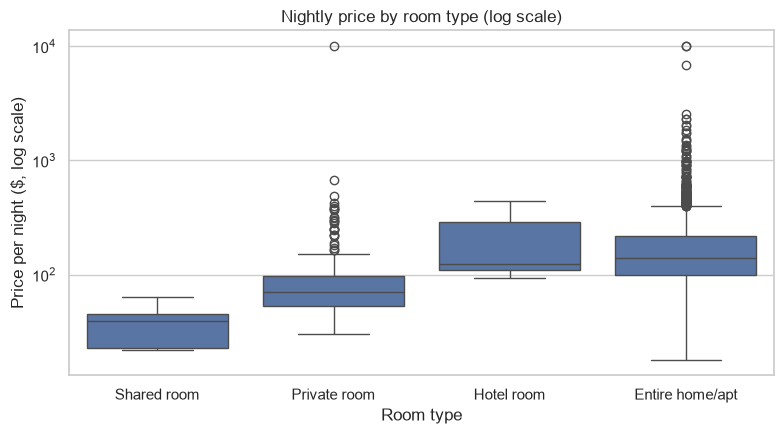

In [19]:
# YOUR CODE HERE
def q90(s):
    return s.quantile(0.90)

room_summary = df_price.groupby("room_type")["price"].agg(
    count="count",
    median="median",
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    p90=q90,
    max="max",
).round(1)
room_summary["share_of_listings_pct"] = (room_summary["count"] / room_summary["count"].sum() * 100).round(1)
display(room_summary.sort_values("median"))

order = room_summary.sort_values("median").index
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_price, x="room_type", y="price", order=order, showfliers=True)
plt.yscale("log")
plt.title("Nightly price by room type (log scale)")
plt.xlabel("Room type")
plt.ylabel("Price per night ($, log scale)")
plt.tight_layout()
plt.show()

**Interpretation:**


## Q18 (4 points). Overall and within-group patterns

Consider the claim: **“Listings with more reviews tend to have lower prices.”**

Check whether the pattern looks the same in the full dataset and within the `room_type` groups. You may use a visualization, grouped summaries, or both.

After accounting for room type, is the claim supported, weakened, or more complicated than it first appeared? Give one reason this pattern should not be interpreted as causal.


In [20]:
# YOUR CODE HERE
# 1. Overall correlation (Spearman rank correlation handles price skewness well)
print("Overall correlation:", df["price"].corr(df["number_of_reviews"], method="spearman"))

# 2. Within-group correlations across room types
print("\nBy room type:\n", df.groupby("room_type")[["price", "number_of_reviews"]].corr(method="spearman").iloc[0::2, 1])

Overall correlation: -0.20314520842707307

By room type:
 room_type             
Entire home/apt  price   -0.216273
Hotel room       price   -0.663342
Private room     price   -0.222825
Shared room      price    0.251502
Name: number_of_reviews, dtype: float64


**Conclusion about the claim:**

**Why the pattern is not necessarily causal:**


## Q19 (4 points). Looking beyond correlation

Create a correlation table or heatmap containing price and at least four relevant numerical variables. Treat it as a starting point rather than a conclusion.

Choose one relationship that deserves a closer look and one correlation that may be misleading because of skew, grouping, the way a variable is defined, or another data issue. For either pair, examine the data in a second way, for example, with a plot, grouped summary, or selected rows. What does this reveal that the correlation coefficient does not?


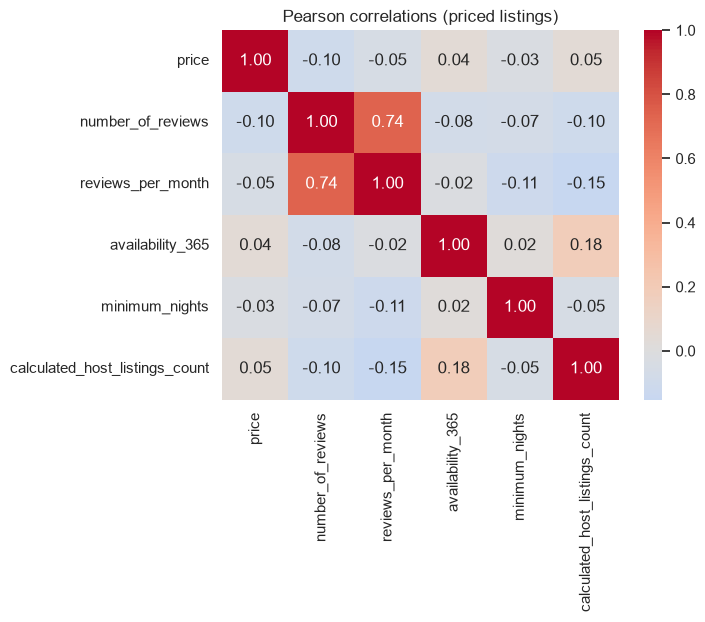

Spearman: 0.22
                                count  median
calculated_host_listings_count               
1                                1203   119.0
2                                 403   124.0
3-5                               355   139.0
6+                                576   186.5


In [21]:
# YOUR CODE HERE
cols = ["price", "number_of_reviews", "reviews_per_month", "availability_365",
        "minimum_nights", "calculated_host_listings_count"]
sns.heatmap(df_price[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson correlations (priced listings)"); plt.show()

# Second look: price vs host listing count
print("Spearman:", round(df_price["price"].corr(df_price["calculated_host_listings_count"], method="spearman"), 2))
groups = pd.cut(df_price["calculated_host_listings_count"], [0, 1, 2, 5, 1000], labels=["1", "2", "3-5", "6+"])
print(df_price.groupby(groups)["price"].agg(["count", "median"]))

**Interpretation:**
It seems, when using a measurement that is resistant to extreme outliers (Spearman = 0.22) or looking at median prices, a trend shows that hosts with more listings usually charge higher prices.


## Q20 (4 points). Your own EDA question

Choose an audience: a traveler, a prospective host, or a city analyst. Write one Asheville question for that audience that has not already been answered in Q12–Q19. Use at least two variables, and make the question specific enough to guide a decision or a follow-up analysis.

### AI Copilot Activity 3: Planning the visualization

Ask an AI assistant to recommend a visualization and provide code. Record its recommendation, whether you agree with it, and any changes you made.

Create the final visualization and interpret it for your chosen audience. Include one alternative explanation for the pattern and one conclusion that cannot be made from these data.

**Audience and question:** The prospective host. 

**Choice of visualization:** Box plot per host group on a log scale. It shows medians and spread despite the skew.

**AI recommendation and changes made:**
The AI suggested a box plot of price by host size on a log scale. I agreed. I limited it to entire homes so room type does not drive the gap, and I chose the 5-listing cutoff. (Anthropic, Claude, response to "recommend a visualization and code for price by host size," accessed 9-25-26.)


               count     25%    50%    75%
host                                      
1-4 listings  1725.0   96.00  126.0  197.0
5+ listings    582.0  127.25  187.0  265.0


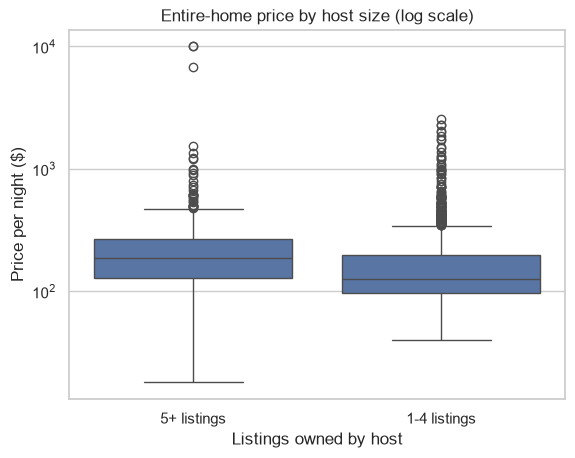

In [22]:
# Create your final visualization.

# YOUR CODE HERE
homes = df_price[df_price["room_type"] == "Entire home/apt"].copy()
homes["host"] = np.where(homes["calculated_host_listings_count"] >= 5, "5+ listings", "1-4 listings")
print(homes.groupby("host")["price"].describe()[["count", "25%", "50%", "75%"]])

sns.boxplot(data=homes, x="host", y="price"); plt.yscale("log")
plt.title("Entire-home price by host size (log scale)")
plt.xlabel("Listings owned by host"); plt.ylabel("Price per night ($)")
plt.show()

**Interpretation:** Hosts with 5+ listings have a median of 187$ a night, while hosts with 1-4 hostings have a median of 126 per night. Supports the Q19 findings.

**Alternative explanation:** Multi-listing hosts may own larger or better-located homes. The data has no bedroom count to check this, but intuitively, multiple listings = more success. 

**What the data cannot establish:** That owning more listings causes higher prices. We cannot infer that a host with more listings = higher prices per night.


# Part E (5 points). Communicating the analysis

## Q21 (3 points). Brief summary for a general audience

Write 120–180 words for a reader who is not a data scientist. Focus on one conclusion about Asheville Airbnb prices that is supported by your analysis.

Give the evidence behind the conclusion and mention one cleaning or measurement choice that matters. Also discuss one subgroup, unusual case, or missing-data issue that affects the interpretation. End with a stronger claim that these data do not support.

Write this as a short, connected explanation rather than a list of answers from earlier questions.

**Summary:** A typical airbnb in Ashevill costs $133 a night, where most listings cost between $95 and $211. This is when not considering the extreme outliers. There 3 listings listed at $9,999. This seems to be placeholder prices rather than actual prices. Also, there are 315 listings that show no prices. Lastly, there are differen room types, where private rooms have a median price of $71, while entire homes are $139. These data records seem to ask for prices on one date, so it is possible that we are not 100% sure what visitors actually pay for a say.


## Q22 (2 points). AI-use disclosure

List the AI tools used in this assignment, including the required Copilot activities. If you used AI only for those activities, say so. AI-assisted wording, code, or ideas should also be acknowledged near the relevant answer.

| Item | Your response |
|---|---|
| Tool and model/version, if available | Anthropic, Claude (Claude Sonnet 5) |
| Question(s) where used | AI Copilot Activities |
| What help I requested |Code for Q8, Q12 -> onwards |
| Output I used or adapted |  Code for the reshape, joins, Anscombe plots, missing-value audit, price summaries, Q17, Q18, Q16, Q19.|
| How I checked the output |I ran every code cell on Asheville_listings.csv (listings.csv for my filesystem) and compared the printed numbers with the written answers.  |
| What I changed or did not use | I rewrote Q9, Q11, Q15, Q19, Q20, and Q21 in my own words and cut the AI drafts down to shorter answers  |
| Location of citation(s) |   Under Q4, the Q8 code cell, Q12, Q14 (AI recommendation), and Q20 (AI recommendation) |


# Final submission checklist

- [x] I answered every written prompt.
- [ ] My reshaped and integrated tables have the intended unit of observation.
- [ ] Every figure has a meaningful title and labeled axes.
- [ ] I reported units, denominators, and excluded observations where relevant.
- [ ] I distinguished association from causation.
- [ ] I preserved the original Airbnb dataframe as `df_raw`.
- [ ] I disclosed and cited every use of an AI tool.
- [ ] I verified AI-assisted claims and code with data or documentation.
- [ ] I restarted the kernel and ran all cells successfully.
- [ ] I submitted both `.ipynb` and `.html` files.
